In [1]:
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import Dataset
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, TrainingArguments, Trainer, set_seed

project_root = Path.cwd()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import dataframe_to_hf_dataset, tokenize_hf_dataset, compute_trainer_metrics


c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
RANDOM_SEED = 42
MODEL_NAME = "distilbert-base-uncased"
LABELS = ["negative", "neutral", "positive"]

set_seed(RANDOM_SEED)

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

processed_dir = project_root / "data" / "processed"
models_dir = project_root / "models"
metrics_dir = project_root / "outputs" / "metrics"
predictions_dir = project_root / "outputs" / "predictions"
figures_dir = project_root / "outputs" / "figures"

for folder in [models_dir, metrics_dir, predictions_dir, figures_dir]:
    folder.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(processed_dir / "train.csv")
validation_df = pd.read_csv(processed_dir / "validation.csv")

print("Train examples:", len(train_df))
print("Validation examples:", len(validation_df))

Train examples: 3385
Validation examples: 725


In [3]:

def dataframe_to_dataset(dataframe):
    return Dataset.from_pandas(
        dataframe[
            ["sentence", "label_id"]
        ].rename(columns={"label_id": "labels"}),
        preserve_index=False
    )

train_dataset = dataframe_to_dataset(train_df)
validation_dataset = dataframe_to_dataset(validation_df)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        max_length=256
    )

tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True
)

tokenized_validation = validation_dataset.map(
    tokenize_function,
    batched=True
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

Map: 100%|██████████| 725/725 [00:00<00:00, 7280.17 examples/s]


In [4]:

def compute_metrics(eval_prediction):
    logits, true_labels = eval_prediction

    predicted_labels = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy_score(true_labels, predicted_labels),
        "macro_f1": f1_score(
            true_labels,
            predicted_labels,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        )
    }

In [5]:

id_to_label = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

label_to_id = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id_to_label,
    label2id=label_to_id
)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 2706.72it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [6]:
training_args = TrainingArguments(
    output_dir=str(models_dir / "distilbert_checkpoints"),
    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    num_train_epochs=2,
    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    logging_strategy="steps",
    logging_steps=20,

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,

    report_to="none",
    seed=RANDOM_SEED
)

In [7]:

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_validation,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

trainer.train()

print("Full fine-tuning completed.")

c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.447111,0.439930,0.820690,0.780773
2,0.347456,0.396869,0.833103,0.810565


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.48it/s]
c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.31it/s]


Full fine-tuning completed.


In [8]:

validation_metrics = trainer.evaluate()

print(validation_metrics)

c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.347456,0.396869,2,0.833103,0.810565


{'eval_loss': 0.396869033575058, 'eval_accuracy': 0.833103448275862, 'eval_macro_f1': 0.8105653046682938}


In [9]:

final_model_dir = models_dir / "distilbert_financial_sentiment"

trainer.save_model(final_model_dir)
tokenizer.save_pretrained(final_model_dir)

print("Saved final model to:", final_model_dir)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.24it/s]

Saved final model to: c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\models\distilbert_financial_sentiment


In [10]:

prediction_output = trainer.predict(tokenized_validation)

validation_logits = prediction_output.predictions
validation_predicted_ids = np.argmax(validation_logits, axis=1)

shifted_logits = validation_logits - np.max(
    validation_logits,
    axis=1,
    keepdims=True
)

probabilities = np.exp(shifted_logits)
probabilities = probabilities / probabilities.sum(
    axis=1,
    keepdims=True
)

validation_predictions = validation_df.copy()

validation_predictions["predicted_label"] = [
    id_to_label[prediction]
    for prediction in validation_predicted_ids
]

validation_predictions["confidence"] = probabilities.max(axis=1)

validation_predictions["negative_probability"] = probabilities[:, 0]
validation_predictions["neutral_probability"] = probabilities[:, 1]
validation_predictions["positive_probability"] = probabilities[:, 2]

display(
    validation_predictions[
        [
            "sentence",
            "label",
            "predicted_label",
            "confidence"
        ]
    ].head()
)

c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


,sentence,label,predicted_label,confidence
0,"Outotec 's scope of delivery includes design ,...",neutral,neutral,0.977895
1,The company website is www.ahlstrom.com .,neutral,neutral,0.976007
2,The group reiterated its forecast that handset...,neutral,neutral,0.507779
3,Finnish IT solutions provider Affecto Oyj said...,positive,positive,0.916744
4,at 9:00 EET Alma Media 's Annual Report for 20...,neutral,neutral,0.979949


In [11]:

validation_accuracy = accuracy_score(
    validation_predictions["label"],
    validation_predictions["predicted_label"]
)

validation_macro_f1 = f1_score(
    validation_predictions["label"],
    validation_predictions["predicted_label"],
    labels=LABELS,
    average="macro",
    zero_division=0
)

validation_report = classification_report(
    validation_predictions["label"],
    validation_predictions["predicted_label"],
    labels=LABELS,
    output_dict=True,
    zero_division=0
)

print(f"Validation accuracy: {validation_accuracy:.3f}")
print(f"Validation macro F1: {validation_macro_f1:.3f}")

for label in LABELS:
    print(
        f"{label.capitalize()} F1: "
        f"{validation_report[label]['f1-score']:.3f}"
    )

Validation accuracy: 0.833
Validation macro F1: 0.811
Negative F1: 0.806
Neutral F1: 0.877
Positive F1: 0.748


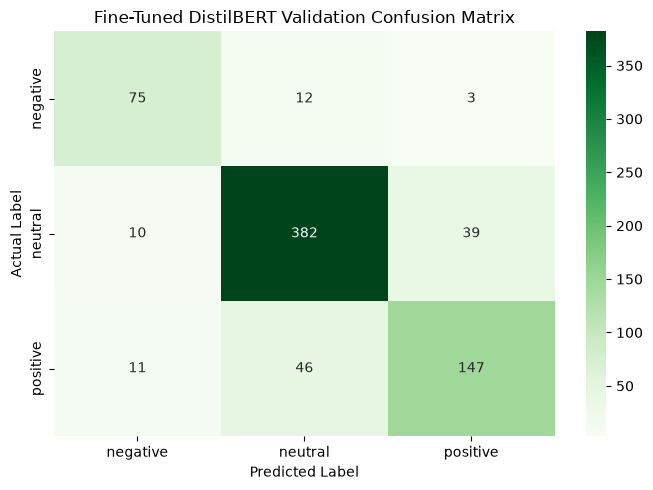

In [12]:
matrix = confusion_matrix(
    validation_predictions["label"],
    validation_predictions["predicted_label"],
    labels=LABELS
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=LABELS,
    yticklabels=LABELS
)

plt.title("Fine-Tuned DistilBERT Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    figures_dir / "finetuned_validation_confusion_matrix.png",
    dpi=200
)

plt.show()

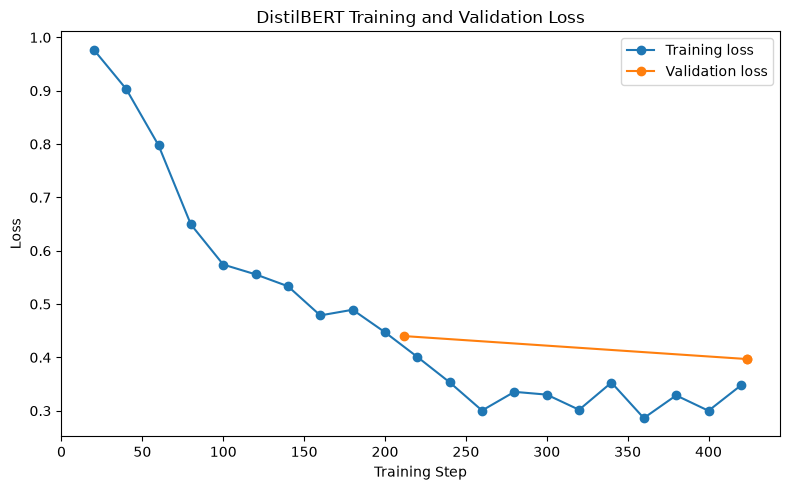

In [13]:

log_history = trainer.state.log_history

training_steps = [
    item["step"]
    for item in log_history
    if "loss" in item
]

training_losses = [
    item["loss"]
    for item in log_history
    if "loss" in item
]

evaluation_steps = [
    item["step"]
    for item in log_history
    if "eval_loss" in item
]

evaluation_losses = [
    item["eval_loss"]
    for item in log_history
    if "eval_loss" in item
]

plt.figure(figsize=(8, 5))

plt.plot(
    training_steps,
    training_losses,
    marker="o",
    label="Training loss"
)

plt.plot(
    evaluation_steps,
    evaluation_losses,
    marker="o",
    label="Validation loss"
)

plt.title("DistilBERT Training and Validation Loss")
plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()

plt.savefig(
    figures_dir / "finetuned_training_validation_loss.png",
    dpi=200
)

plt.show()

In [14]:

finetuned_metrics = {
    "model": MODEL_NAME,
    "training_examples": int(len(train_df)),
    "validation_examples": int(len(validation_df)),
    "epochs": 3,
    "learning_rate": 2e-5,
    "validation_accuracy": round(float(validation_accuracy), 4),
    "validation_macro_f1": round(float(validation_macro_f1), 4),
    "per_class_validation_f1": {
        label: round(
            float(validation_report[label]["f1-score"]),
            4
        )
        for label in LABELS
    }
}

with open(
    metrics_dir / "finetuned_validation_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(finetuned_metrics, file, indent=2)

validation_predictions.to_csv(
    predictions_dir / "finetuned_validation_predictions.csv",
    index=False
)

print(finetuned_metrics)
print("\nSaved validation metrics, predictions, model, and plots.")

{'model': 'distilbert-base-uncased', 'training_examples': 3385, 'validation_examples': 725, 'epochs': 3, 'learning_rate': 2e-05, 'validation_accuracy': 0.8331, 'validation_macro_f1': 0.8106, 'per_class_validation_f1': {'negative': 0.8065, 'neutral': 0.8772, 'positive': 0.7481}}

Saved validation metrics, predictions, model, and plots.
